In [46]:
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import numpy as np

from IPython.display import display, HTML

In [47]:
execution_path = "../../../"

output_folder = (
    "SDDSmoteBoost_Unf_All_Patient_Direct_Base"  # TL + Base - Direct Base folder
)
output_folder = (
    "SDDSmoteBoost_Unf_All_Patient"  #  TL + Base - Pre-Saved Base Models folder
)


RESULT_DIR = f"{execution_path}/Output_Results/{output_folder}/"
print("RESULT_DIR", RESULT_DIR)

# Possible Values: "TL_1_Frozen", "TL_2_Frozen", "TL_3_Frozen", "TL_All_Frozen", "TL_All_Unfrozen"
Architecture_GROUP_List = [
    "TL_All_Unfrozen",
]

Model_Type_list = [
    "K-NN",
    "LogisticRegression",
    "NaiveBayes",
    "SVM",
    "DecisionTree",
]

patient_target_grp = [
    "SB-001",
    "SB-003",
    "SB-008",
    "SB-011",
    "SB-012",
    "SB-022",
    "SB-023",
    "SB-025",
    "SB-028",
    "SB-037",
    "SB-043",
    "SB-056",
    "SB-059",
    "SB-060",
    "SB-070",
    "SB-071",
    "SB-073",
    "SB-078",
    "SB-079",
    "SB-080",
    "SB-082",
    "SB-083",
    "SB-112",
]
print("patient_target_grp", patient_target_grp)

data_processing_columns = [
    "Patient_ID",
    "Pop_Epoch",
    "Pop_Fold",
    "Ind_Epoch",
    "Ind_Fold",
    "Model_Type",
]


# WHEN FALSE, TARGET DATA IS NOT REMOVED FROM ALL PATIENTS DATA
# False for Generalized model, True for Patient-wise Pop Models
bool_remove_target = False

# Number of Folds for running Pop Model
# Possible values : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
num_pop_folds = 5

# Number of Folds for running Ind Model
# Possible values : [3, 4, 5]
num_ind_folds = 3

POPULATION_EPOCH_SIZE_LIST = [100, 300, 500, 700, 1000, 2000, 3000]

PATIENT_EPOCH_SIZE_LIST = [100, 300, 500, 700, 1000, 2000, 3000]

RESULT_DIR ../../..//Output_Results/SDDSmoteBoost_Unf_All_Patient/
patient_target_grp ['SB-001', 'SB-003', 'SB-008', 'SB-011', 'SB-012', 'SB-022', 'SB-023', 'SB-025', 'SB-028', 'SB-037', 'SB-043', 'SB-056', 'SB-059', 'SB-060', 'SB-070', 'SB-071', 'SB-073', 'SB-078', 'SB-079', 'SB-080', 'SB-082', 'SB-083', 'SB-112']


In [48]:
def segregate_identifier(
    index,
    column_return_type,
    POPULATION_EPOCH_SIZE_LIST,
    PATIENT_EPOCH_SIZE_LIST,
    target_grp,
    num_pop_folds,
    num_ind_folds,
    Model_Type_list,
):
    index = str(index).upper()
    if column_return_type == "Pop_Epoch":
        for i in POPULATION_EPOCH_SIZE_LIST:
            if str(i) + "_POP" in index:
                return i
    elif column_return_type == "Ind_Epoch":
        for j in PATIENT_EPOCH_SIZE_LIST:
            if str(j) + "_IND" in index:
                return j
    elif column_return_type == "Patient_ID":
        for i in target_grp:
            if str(i) in index:
                return i
    elif column_return_type == "Pop_Fold":
        for i in [*range(1, num_pop_folds + 1)]:
            if "POP_FOLD_" + str(i) in index:
                return i
    elif column_return_type == "Ind_Fold":
        for i in [*range(1, num_ind_folds + 1)]:
            if "IND_FOLD_" + str(i) in index:
                return i
    elif column_return_type == "Model_Type":
        for i in Model_Type_list:
            if i.upper() in index:
                return i.upper()


def load_csv_to_df(
    eval_data_type,
    RESULT_DIR,
    Architecture_GROUP,
    bool_remove_target,
    data_processing_columns,
    POPULATION_EPOCH_SIZE_LIST,
    PATIENT_EPOCH_SIZE_LIST,
    target_grp,
    num_pop_folds,
    num_ind_folds,
    Model_Type_list,
):
    if bool_remove_target == True:
        suffix = "_evaluation_metrics_TargetRemoved.csv"
    else:
        suffix = "_evaluation_metrics.csv"

    if eval_data_type == "individual":
        eval_data_path = "/diagrams_n_individual_models/Ind_"
    elif eval_data_type == "population":
        eval_data_path = "/diagrams_n_population_models/Pop_"
    elif eval_data_type == "TL-Base":
        eval_data_path = "/diagrams_n_TL-Base_models/TL_Base_"

    file_path = (
        str(RESULT_DIR)
        + "/"
        + Architecture_GROUP
        + eval_data_path
        + Architecture_GROUP
        + suffix
    )

    if os.path.isfile(file_path):
        df = pd.read_csv(file_path, index_col=0)
        for i in data_processing_columns:
            df[i] = df.index.map(
                lambda x: segregate_identifier(
                    x,
                    i,
                    POPULATION_EPOCH_SIZE_LIST,
                    PATIENT_EPOCH_SIZE_LIST,
                    target_grp,
                    num_pop_folds,
                    num_ind_folds,
                    Model_Type_list,
                )
            )
        return df


bool_remove_target_list = [False]  # [True, False]
eval_data_type_list = ["population"]  # ["individual", "population","TL-Base"]


All_eval_dict = {}

for i in eval_data_type_list:
    for j in bool_remove_target_list:
        for Architecture_GROUP in Architecture_GROUP_List:
            All_eval_dict[Architecture_GROUP + "_" + i + "_" + str(j)] = load_csv_to_df(
                i,
                RESULT_DIR,
                Architecture_GROUP,
                j,
                data_processing_columns,
                POPULATION_EPOCH_SIZE_LIST,
                PATIENT_EPOCH_SIZE_LIST,
                patient_target_grp,
                num_pop_folds,
                num_ind_folds,
                Model_Type_list,
            )

# del bool_remove_target_list
# del eval_data_type_list

In [49]:
if "TL-Base" in eval_data_type_list and False in bool_remove_target_list:
    display(All_eval_dict["TL_All_Unfrozen_TL-Base_False"].head(5))
    Un_frozen_All_df = All_eval_dict["TL_All_Unfrozen_TL-Base_False"]
elif "individual" in eval_data_type_list and False in bool_remove_target_list:
    display(All_eval_dict["TL_All_Unfrozen_individual_False"].head(5))
    Un_frozen_All_df = All_eval_dict["TL_All_Unfrozen_individual_False"]
elif "population" in eval_data_type_list and False in bool_remove_target_list:
    display(All_eval_dict["TL_All_Unfrozen_population_False"].head(5))
    Un_frozen_All_df = All_eval_dict["TL_All_Unfrozen_population_False"]
elif "TL-Base" in eval_data_type_list and True in bool_remove_target_list:
    display(All_eval_dict["TL_All_Unfrozen_TL-Base_True"].head(5))
    Un_frozen_All_df = All_eval_dict["TL_All_Unfrozen_TL-Base_True"]
elif "individual" in eval_data_type_list and True in bool_remove_target_list:
    display(All_eval_dict["TL_All_Unfrozen_individual_True"].head(5))
    Un_frozen_All_df = All_eval_dict["TL_All_Unfrozen_individual_True"]
elif "population" in eval_data_type_list and True in bool_remove_target_list:
    display(All_eval_dict["TL_All_Unfrozen_population_True"].head(5))
    Un_frozen_All_df = All_eval_dict["TL_All_Unfrozen_population_True"]

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,...,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard,Patient_ID,Pop_Epoch,Pop_Fold,Ind_Epoch,Ind_Fold,Model_Type
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1,0.522430,0.401235,0.643625,0.218855,0.812016,0.515435,0.283224,0.718081,0.500652,0.522430,...,0.187984,0.356375,0.781145,0.164975,None,100,1,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_2,0.540281,0.404372,0.676190,0.266187,0.796262,0.531224,0.321041,0.731330,0.526186,0.540281,...,0.203738,0.323810,0.733813,0.191214,None,100,2,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_3,0.527740,0.331288,0.724191,0.231760,0.811744,0.521752,0.272727,0.765472,0.519100,0.527740,...,0.188256,0.275809,0.768240,0.157895,None,100,3,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_4,0.542839,0.256410,0.829268,0.263158,0.824242,0.543700,0.259740,0.826748,0.543244,0.542839,...,0.175758,0.170732,0.736842,0.149254,None,100,4,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_5,0.496189,0.250000,0.742378,0.187500,0.806291,0.496896,0.214286,0.773016,0.493651,0.496189,...,0.193709,0.257622,0.812500,0.120000,None,100,5,None,None,None


In [50]:
if "population" in eval_data_type_list:
    filter_df = Un_frozen_All_df[(Un_frozen_All_df["Pop_Epoch"] == 100)]
else:
    filter_df = Un_frozen_All_df[
        (Un_frozen_All_df["Pop_Epoch"] == 100) & (Un_frozen_All_df["Ind_Epoch"] == 3000)
    ]

display(filter_df)

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,...,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard,Patient_ID,Pop_Epoch,Pop_Fold,Ind_Epoch,Ind_Fold,Model_Type
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1,0.522430,0.401235,0.643625,0.218855,0.812016,0.515435,0.283224,0.718081,0.500652,0.522430,...,0.187984,0.356375,0.781145,0.164975,None,100,1,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_2,0.540281,0.404372,0.676190,0.266187,0.796262,0.531224,0.321041,0.731330,0.526186,0.540281,...,0.203738,0.323810,0.733813,0.191214,None,100,2,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_3,0.527740,0.331288,0.724191,0.231760,0.811744,0.521752,0.272727,0.765472,0.519100,0.527740,...,0.188256,0.275809,0.768240,0.157895,None,100,3,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_4,0.542839,0.256410,0.829268,0.263158,0.824242,0.543700,0.259740,0.826748,0.543244,0.542839,...,0.175758,0.170732,0.736842,0.149254,None,100,4,None,None,None
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_5,0.496189,0.250000,0.742378,0.187500,0.806291,0.496896,0.214286,0.773016,0.493651,0.496189,...,0.193709,0.257622,0.812500,0.120000,None,100,5,None,None,None


In [54]:
def grouping_by_patient_model_type(df, groupby_type):
    if groupby_type == "population":
        groupby_columns = ["Pop_Epoch"]
    elif groupby_type == "individual":
        groupby_columns = ["Patient_ID"]
    elif groupby_type == "TL-Base":
        groupby_columns = ["Patient_ID", "Model_Type"]
    return (
        df.groupby(groupby_columns)
        .mean(numeric_only=True)
        .drop(columns=data_processing_columns, errors="ignore")
    )

In [55]:
grouped_analysis = grouping_by_patient_model_type(
    filter_df, "population"
)  # ["individual", "population","TL-Base"]
display(grouped_analysis)

grouped_analysis.to_csv("Model_Analysis_by_patient_Epochs_100_3000_TL_Pop.csv")

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Pop_Epoch,,,,,,,,,,,,,,,
100,0.525896,0.328661,0.723131,0.233492,0.810111,0.521802,0.270204,0.762929,0.516567,0.525896,0.671339,0.189889,0.276869,0.766508,0.156668


In [5]:
def grouping_df(df):
    grouped_dfs = {}

    for column in data_processing_columns:
        grouped_df = (
            df.groupby([column])
            .mean(numeric_only=True)
            .drop(columns=data_processing_columns, errors="ignore")
        )
        grouped_dfs[column] = grouped_df

    return grouped_dfs


grouped_dfs = grouping_df(Un_frozen_All_df)

# Access the grouped DataFrames using column_type
grp_df_patient_id = grouped_dfs["Patient_ID"]
grp_df_pop_epoch = grouped_dfs["Pop_Epoch"]
grp_df_ind_epoch = grouped_dfs["Ind_Epoch"]
grp_df_pop_fold = grouped_dfs["Pop_Fold"]
grp_df_ind_fold = grouped_dfs["Ind_Fold"]

# Display the grouped DataFrames
display(grp_df_patient_id)
display(grp_df_pop_epoch)
display(grp_df_ind_epoch)
# display(grp_df_pop_fold)
# display(grp_df_ind_fold)

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Pop_Epoch,,,,,,,,,,,,,,,
100,0.815300,0.759833,0.870767,0.617828,0.934421,0.776125,0.666918,0.899332,0.783125,0.815300,0.240167,0.065544,0.129233,0.382068,0.519092
300,0.808542,0.751164,0.865921,0.606085,0.932219,0.769152,0.656048,0.895356,0.775702,0.808542,0.248836,0.067502,0.134079,0.393671,0.507305
500,0.805296,0.743790,0.866803,0.604592,0.930169,0.767380,0.651865,0.894810,0.773338,0.805296,0.256210,0.069448,0.133197,0.394501,0.502749
700,0.806539,0.747332,0.865746,0.604759,0.931060,0.767910,0.653553,0.894626,0.774090,0.806539,0.252668,0.068487,0.134254,0.394857,0.504700
1000,0.801388,0.740733,0.862043,0.597093,0.928627,0.762860,0.645451,0.891081,0.768266,0.801388,0.259267,0.070579,0.137957,0.402148,0.495529
2000,0.788259,0.720365,0.856154,0.581891,0.923380,0.752636,0.629151,0.885210,0.757180,0.788259,0.279635,0.075378,0.143846,0.417212,0.478068
3000,0.787267,0.717470,0.857064,0.581238,0.923177,0.752207,0.627297,0.885677,0.756487,0.787267,0.282530,0.076375,0.142936,0.416692,0.477115


,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Ind_Epoch,,,,,,,,,,,,,,,
100,0.730288,0.652825,0.807751,0.480033,0.902663,0.691348,0.538464,0.849316,0.693890,0.730288,0.347175,0.097129,0.192249,0.519655,0.385919
300,0.794655,0.732405,0.856905,0.584261,0.926411,0.755336,0.634716,0.887492,0.761104,0.794655,0.267595,0.073068,0.143095,0.415426,0.482572
500,0.809768,0.749903,0.869632,0.611319,0.932047,0.771683,0.658259,0.897226,0.777743,0.809768,0.250097,0.067502,0.130368,0.388091,0.507861
700,0.813746,0.754932,0.872559,0.618471,0.933255,0.775863,0.664753,0.899213,0.781983,0.813746,0.245068,0.066086,0.127441,0.380905,0.515481
1000,0.816810,0.758735,0.874885,0.623784,0.934815,0.779299,0.669655,0.901106,0.785380,0.816810,0.241265,0.064734,0.125115,0.375314,0.520913
2000,0.822817,0.765512,0.880122,0.635513,0.936629,0.786071,0.680672,0.905000,0.792836,0.822817,0.234488,0.062642,0.119878,0.363446,0.534110
3000,0.824279,0.766037,0.882522,0.639817,0.937136,0.788476,0.683450,0.906619,0.795034,0.824279,0.233963,0.062240,0.117478,0.358587,0.537362


In [6]:
idxmax_result = pd.DataFrame()
for df_name, df in grouped_dfs.items():
    sorted_df = df.sort_values(by=df_name)
    temp_result = pd.DataFrame(sorted_df.idxmax(), columns=[df_name])
    idxmax_result = pd.concat([idxmax_result, temp_result], axis=1)

display(idxmax_result)

,Patient_ID,Pop_Epoch,Pop_Fold,Ind_Epoch,Ind_Fold,Model_Type
Weighted Accuracy,SB-011,100,3,3000,3,NAIVEBAYES
Sensitivity/Recall,SB-012,100,3,3000,3,K-NN
Specificity,SB-011,100,1,3000,3,NAIVEBAYES
Precision_class0,SB-012,100,1,3000,3,NAIVEBAYES
Precision_class1,SB-011,100,3,3000,3,K-NN
Precision_avg,SB-012,100,3,3000,3,NAIVEBAYES
F1_class0,SB-012,100,3,3000,3,NAIVEBAYES
F1_class1,SB-011,100,1,3000,3,NAIVEBAYES
F1_avg,SB-011,100,3,3000,3,NAIVEBAYES
auc_roc_score,SB-011,100,3,3000,3,NAIVEBAYES


,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Pop_Epoch,,,,,,,,,,,,,,,
100,0.815300,0.759833,0.870767,0.617828,0.934421,0.776125,0.666918,0.899332,0.783125,0.815300,0.240167,0.065544,0.129233,0.382068,0.519092
300,0.808542,0.751164,0.865921,0.606085,0.932219,0.769152,0.656048,0.895356,0.775702,0.808542,0.248836,0.067502,0.134079,0.393671,0.507305
500,0.805296,0.743790,0.866803,0.604592,0.930169,0.767380,0.651865,0.894810,0.773338,0.805296,0.256210,0.069448,0.133197,0.394501,0.502749
700,0.806539,0.747332,0.865746,0.604759,0.931060,0.767910,0.653553,0.894626,0.774090,0.806539,0.252668,0.068487,0.134254,0.394857,0.504700
1000,0.801388,0.740733,0.862043,0.597093,0.928627,0.762860,0.645451,0.891081,0.768266,0.801388,0.259267,0.070579,0.137957,0.402148,0.495529
2000,0.788259,0.720365,0.856154,0.581891,0.923380,0.752636,0.629151,0.885210,0.757180,0.788259,0.279635,0.075378,0.143846,0.417212,0.478068
3000,0.787267,0.717470,0.857064,0.581238,0.923177,0.752207,0.627297,0.885677,0.756487,0.787267,0.282530,0.076375,0.142936,0.416692,0.477115


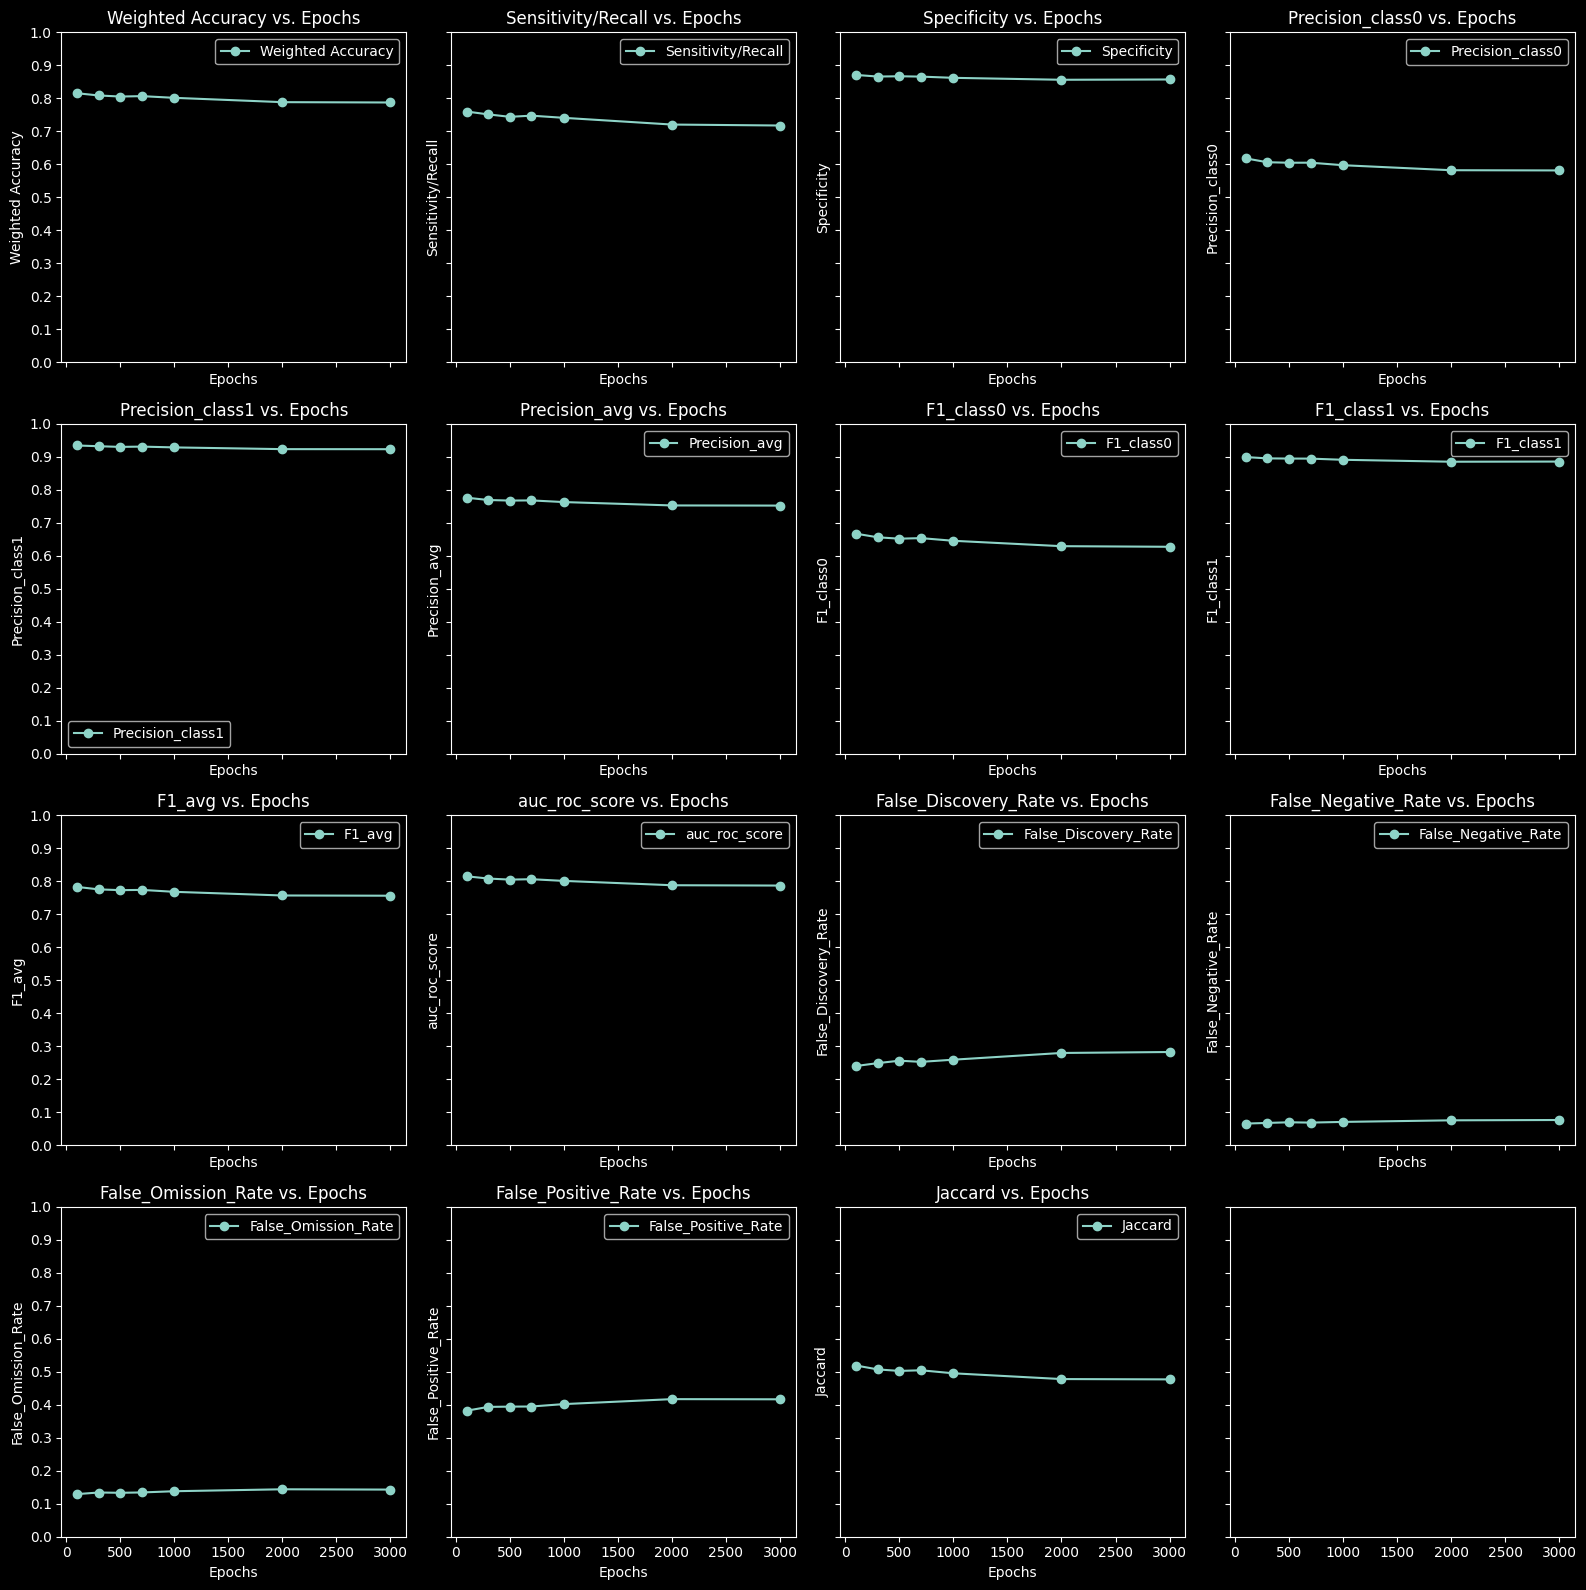

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Ind_Epoch,,,,,,,,,,,,,,,
100,0.730288,0.652825,0.807751,0.480033,0.902663,0.691348,0.538464,0.849316,0.693890,0.730288,0.347175,0.097129,0.192249,0.519655,0.385919
300,0.794655,0.732405,0.856905,0.584261,0.926411,0.755336,0.634716,0.887492,0.761104,0.794655,0.267595,0.073068,0.143095,0.415426,0.482572
500,0.809768,0.749903,0.869632,0.611319,0.932047,0.771683,0.658259,0.897226,0.777743,0.809768,0.250097,0.067502,0.130368,0.388091,0.507861
700,0.813746,0.754932,0.872559,0.618471,0.933255,0.775863,0.664753,0.899213,0.781983,0.813746,0.245068,0.066086,0.127441,0.380905,0.515481
1000,0.816810,0.758735,0.874885,0.623784,0.934815,0.779299,0.669655,0.901106,0.785380,0.816810,0.241265,0.064734,0.125115,0.375314,0.520913
2000,0.822817,0.765512,0.880122,0.635513,0.936629,0.786071,0.680672,0.905000,0.792836,0.822817,0.234488,0.062642,0.119878,0.363446,0.534110
3000,0.824279,0.766037,0.882522,0.639817,0.937136,0.788476,0.683450,0.906619,0.795034,0.824279,0.233963,0.062240,0.117478,0.358587,0.537362


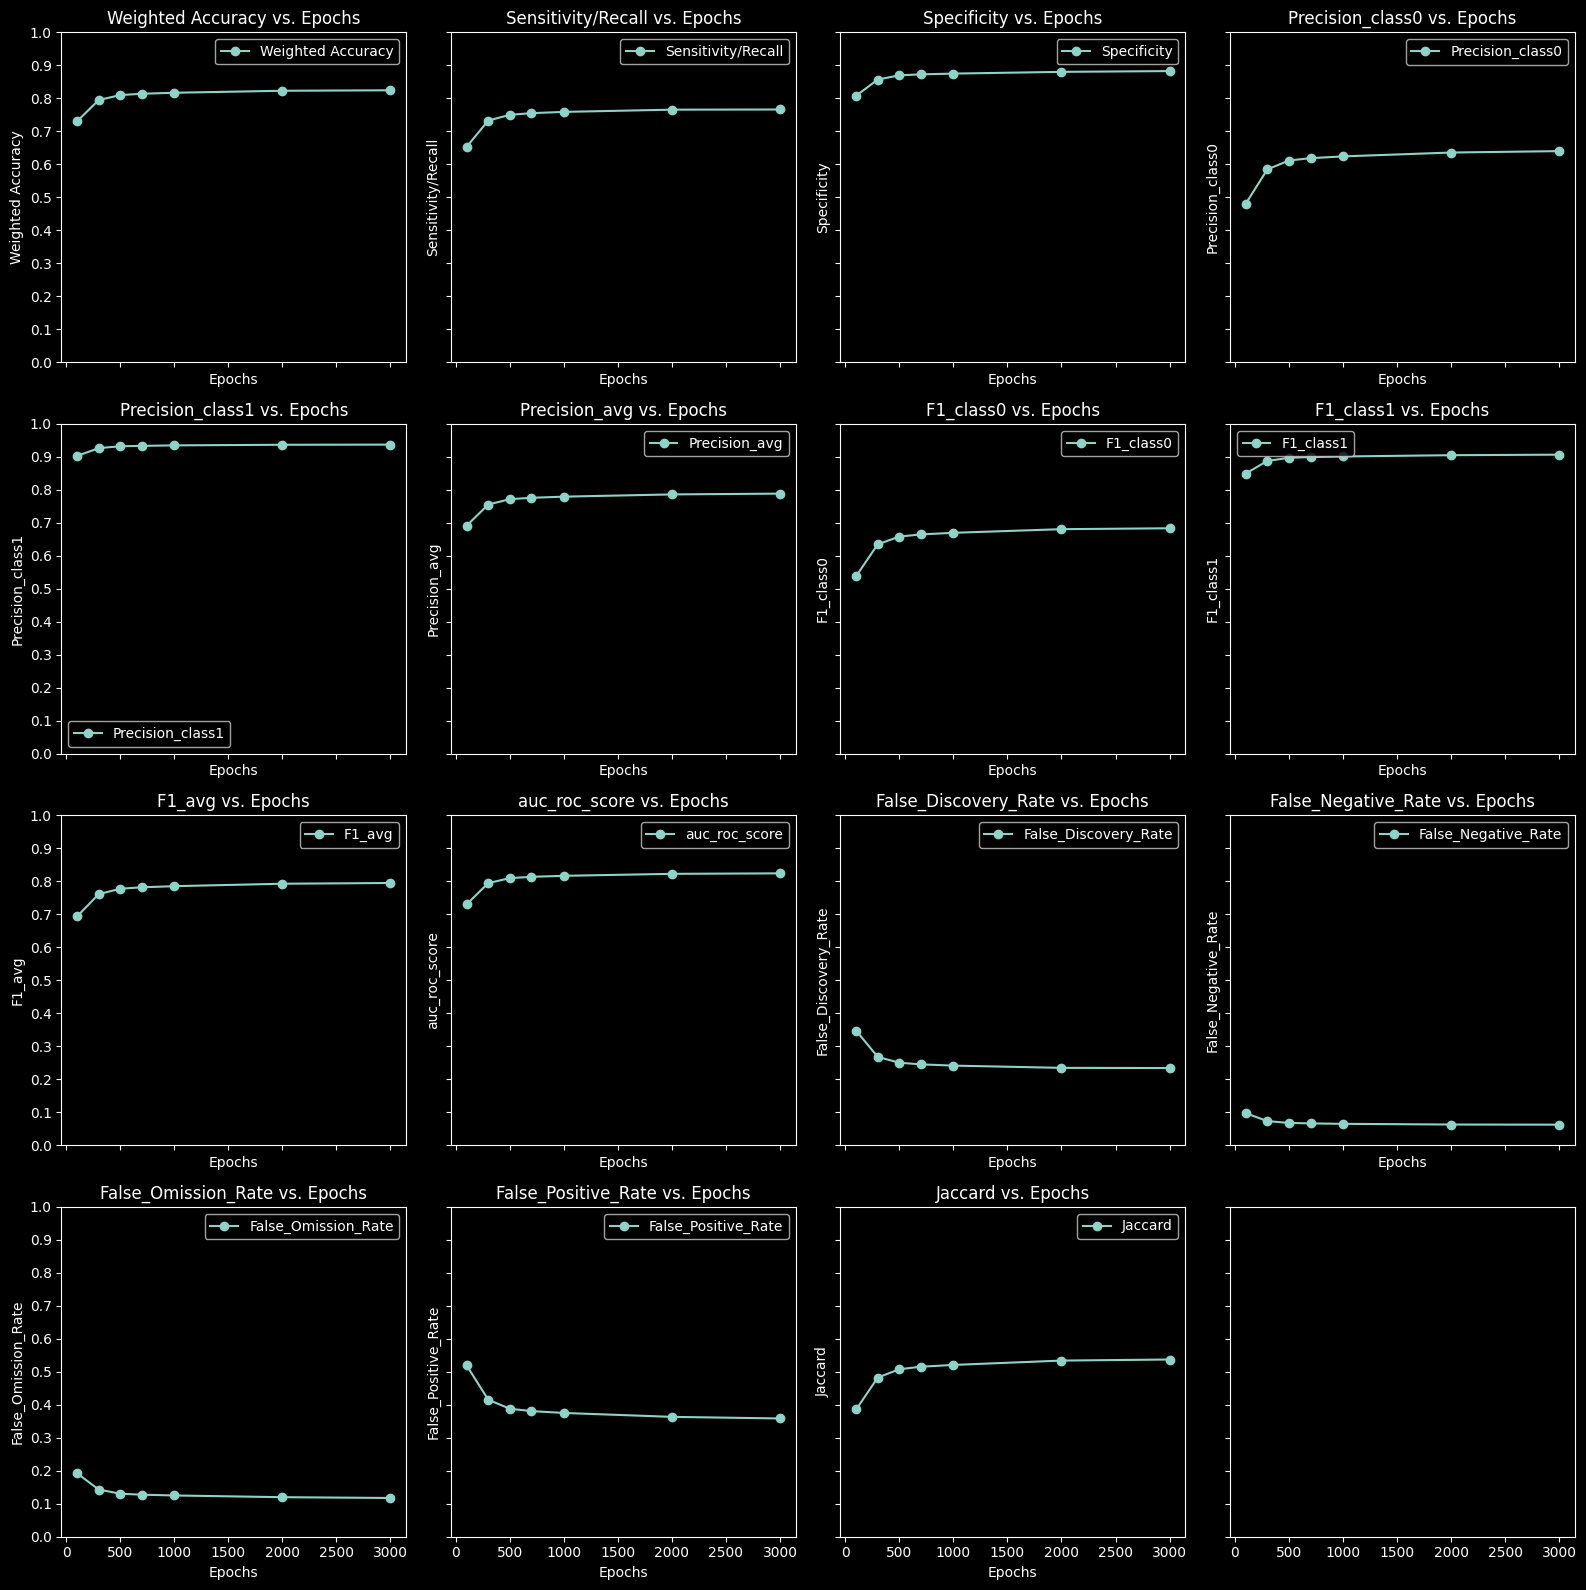

In [8]:
def visualize_arch_epochs(
    df, epoch_type, filepath, Architecture_GROUP, PATIENT_EPOCH_SIZE_LIST
):
    # Sample DataFrame (replace this with your actual DataFrame)

    data = df[epoch_type]

    df = pd.DataFrame(data)

    display(df)

    # Determine the number of rows and columns in the subplot grid

    num_cols = 4

    num_rows = -(
        -len(df.columns) // num_cols
    )  # Ceiling division to get the number of rows

    # Create subplots

    fig, axes = plt.subplots(
        nrows=num_rows, ncols=num_cols, figsize=(16, 16), sharey=True, sharex=True
    )

    # Plot each column against the 'epochs' column

    for idx, column in enumerate(data.columns):  # Exclude 'epochs' column
        row = idx // num_cols

        col = idx % num_cols

        axes[row, col].plot(
            PATIENT_EPOCH_SIZE_LIST, df[column], marker="o", label=column
        )

        axes[row, col].set_xlabel("Epochs")

        y_ticks = np.arange(0.0, 1.1, 0.1)

        axes[row, col].set_yticks(y_ticks)

        axes[row, col].set_yticklabels(["{:.1f}".format(val) for val in y_ticks])

        axes[row, col].set_ylabel(column)

        axes[row, col].set_title(f"{column} vs. Epochs")

        axes[row, col].legend()

    # Adjust layout

    plt.tight_layout()

    plt.savefig(
        f"{filepath}/{Architecture_GROUP}/{Architecture_GROUP}_{epoch_type}.png"
    )

    plt.show()


visualize_arch_epochs(
    grouped_dfs, "Pop_Epoch", RESULT_DIR, Architecture_GROUP, PATIENT_EPOCH_SIZE_LIST
)


visualize_arch_epochs(
    grouped_dfs, "Ind_Epoch", RESULT_DIR, Architecture_GROUP, PATIENT_EPOCH_SIZE_LIST
)

In [9]:
def combining_top_percent_df(df, columns_list, top_percent=10):
    top_percent_value = int(top_percent / 100 * len(df))
    combined_top_percent_dfs = pd.DataFrame()

    for column in columns_list:
        temp_df = df.sort_values(by=column, ascending=False).head(top_percent_value)[
            columns_list
            + ["Patient_ID", "Pop_Epoch", "Pop_Fold", "Ind_Epoch", "Ind_Fold"]
        ]

        combined_top_percent_dfs = pd.concat(
            [combined_top_percent_dfs, temp_df], axis=0
        )
    return combined_top_percent_dfs


columns_list = {
    "All Columns": [
        "Weighted Accuracy",
        "Sensitivity/Recall",
        "Specificity",
        "Precision_class0",
        "Precision_class1",
        "Precision_avg",
        "F1_class0",
        "F1_class1",
        "F1_avg",
        "auc_roc_score",
        "False_Discovery_Rate",
        "False_Negative_Rate",
        "False_Omission_Rate",
        "False_Positive_Rate",
        "Jaccard",
    ],
    "Priority Columns": [
        "Weighted Accuracy",
        "Sensitivity/Recall",
        "Specificity",
        "Precision_avg",
    ],
}

percent_list = np.arange(10, 60, 10)

for column_type, column_values in columns_list.items():
    print(f"List of {column_type}: {column_values}", "\n")


epoch_type_list = ["Pop_Epoch", "Ind_Epoch"]

pop_epoch_df = pd.DataFrame()
ind_epoch_df = pd.DataFrame()

for epoch_type in epoch_type_list:
    epoch_percent_list = []
    epoch_all_column_list = []
    epoch_priority_column_list = []

    for percent_value in percent_list:
        epoch_percent_list.append(percent_value)

        for column_type, column_values in columns_list.items():
            combined_top_percent_df = combining_top_percent_df(
                Un_frozen_All_df, column_values, percent_value
            )
            temp_df = pd.DataFrame(
                combined_top_percent_df.value_counts(epoch_type),
                columns=[f"{epoch_type}_top_{percent_value}%_{column_type}"],
            )
            display(temp_df)
            if column_type == "Priority Columns":
                epoch_priority_column_list.append(
                    combined_top_percent_df.value_counts(epoch_type).idxmax()
                )
            elif column_type == "All Columns":
                epoch_all_column_list.append(
                    combined_top_percent_df.value_counts(epoch_type).idxmax()
                )

    if epoch_type == "Pop_Epoch":
        pop_epoch_df = pd.DataFrame(
            data={
                "epoch_percent_list": epoch_percent_list,
                "epoch_priority_column_list": epoch_priority_column_list,
                "epoch_all_column_list": epoch_all_column_list,
            },
            columns=[
                "epoch_percent_list",
                "epoch_priority_column_list",
                "epoch_all_column_list",
            ],
        )
        pop_epoch_df.set_index("epoch_percent_list", inplace=True)
    elif epoch_type == "Ind_Epoch":
        ind_epoch_df = pd.DataFrame(
            data={
                "epoch_percent_list": epoch_percent_list,
                "epoch_priority_column_list": epoch_priority_column_list,
                "epoch_all_column_list": epoch_all_column_list,
            },
            columns=[
                "epoch_percent_list",
                "epoch_priority_column_list",
                "epoch_all_column_list",
            ],
        )
        ind_epoch_df.set_index("epoch_percent_list", inplace=True)

List of All Columns: ['Weighted Accuracy', 'Sensitivity/Recall', 'Specificity', 'Precision_class0', 'Precision_class1', 'Precision_avg', 'F1_class0', 'F1_class1', 'F1_avg', 'auc_roc_score', 'False_Discovery_Rate', 'False_Negative_Rate', 'False_Omission_Rate', 'False_Positive_Rate', 'Jaccard'] 

List of Priority Columns: ['Weighted Accuracy', 'Sensitivity/Recall', 'Specificity', 'Precision_avg'] 



,Pop_Epoch_top_10%_All Columns
Pop_Epoch,
100,15767
300,14738
700,14735
3000,14410
500,14075
1000,13809
2000,13341


,Pop_Epoch_top_10%_Priority Columns
Pop_Epoch,
100,4690
700,4123
300,4088
500,3897
1000,3666
3000,3343
2000,3093


,Pop_Epoch_top_20%_All Columns
Pop_Epoch,
100,31624
300,29596
700,29023
500,28376
3000,28103
1000,27609
2000,27419


,Pop_Epoch_top_20%_Priority Columns
Pop_Epoch,
100,9194
300,8253
700,7963
500,7785
1000,7343
3000,6721
2000,6541


...

,Ind_Epoch_top_30%_Priority Columns
Ind_Epoch,
3000,15285
2000,14980
1000,13203
700,12738
500,11797
300,9468
100,3229


,Ind_Epoch_top_40%_All Columns
Ind_Epoch,
3000,65414
2000,64608
1000,60701
700,59921
500,57737
300,53495
100,41624


,Ind_Epoch_top_40%_Priority Columns
Ind_Epoch,
3000,19610
2000,19281
1000,17516
700,16911
500,15890
300,13279
100,5113


,Ind_Epoch_top_50%_All Columns
Ind_Epoch,
3000,80312
2000,79371
1000,76874
700,75233
500,73654
300,68190
100,50756


,Ind_Epoch_top_50%_Priority Columns
Ind_Epoch,
3000,23653
2000,23174
1000,21829
700,21073
500,20172
300,17112
100,7491


In [10]:
display("Pop Epoch List", pop_epoch_df)
display("Ind Epoch List", ind_epoch_df)

'Pop Epoch List'

,epoch_priority_column_list,epoch_all_column_list
epoch_percent_list,,
10,100,100
20,100,100
30,100,100
40,100,100
50,100,100


'Ind Epoch List'

,epoch_priority_column_list,epoch_all_column_list
epoch_percent_list,,
10,3000,3000
20,3000,3000
30,3000,3000
40,3000,3000
50,3000,3000


# 1000_100 has most number of high column_values in top 10% of each columns i.e Weighted Accuracy, Sensitivity/Recall, Specificity

# However, after adding 2000 and 3000 epochs, we should consider 2000_100 as best epoch combination, as its at top in most cases

# Point of note - 3000 for pop epoch is best when considering all columns and top 10% for those columns

### List of All Columns: ['Weighted Accuracy', 'Sensitivity/Recall', 'Specificity', 'Precision_class0', 'Precision_class1', 'Precision_avg', 'F1_class0', 'F1_class1', 'F1_avg', 'auc_roc_score', 'False_Discovery_Rate', 'False_Negative_Rate', 'False_Omission_Rate', 'False_Positive_Rate', 'Jaccard']

### List of Priority Columns: ['Weighted Accuracy', 'Sensitivity/Recall', 'Specificity', 'Precision_avg']

### 'Pop Epoch List'

### percent priority_column all_column

#### 10 2000 3000

#### 20 2000 3000

#### 30 2000 2000

#### 40 2000 2000

#### 50 2000 2000

### 'Ind Epoch List'

### percent priority_column all_column

#### 10 100 100

#### 20 100 100

#### 30 100 100

#### 40 100 100

#### 50 2000 100
